### Prof. Alfio Ferrara

# Cercare nei testi

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente abbiamo trovato un modo di rappresentare i documenti con vettori di pesi (tf e tf-idf). Ora lo usiamo per un compito concreto: **rispondere a una domanda**. Una persona scrive qualche parola, la macchina restituisce i documenti nell'ordine in cui pensa possano interessarle. È il cuore di un motore di ricerca.

Faremo tre cose: costruire il motore passo per passo, **misurare** quanto funziona bene, e confrontare due versioni dello stesso motore, una con la sola tf e una con tf-idf.

## Il corpus e i pesi

Riprendiamo i 100 testi sulle città e i pesi del notebook precedente: conteggi, tf, idf e tf-idf. Il codice è lo stesso di L08.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy

nlp = spacy.load('it_core_news_lg')

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

nomi = [voce['citta'] for voce in dataset]
clima = pd.Series([voce['clima'] for voce in dataset], index=nomi)

def token_alfabetici(testo):
    return [t.text.lower() for t in nlp.tokenizer(testo) if t.is_alpha]

documenti = {voce['citta']: token_alfabetici(voce['testo']) for voce in dataset}
vocabolario = sorted({p for parole in documenti.values() for p in parole})

def conta(parole, vocabolario):
    posizione = {p: i for i, p in enumerate(vocabolario)}
    riga = np.zeros(len(vocabolario))
    for p in parole:
        if p in posizione:
            riga[posizione[p]] += 1
    return riga

conteggi = pd.DataFrame([conta(documenti[n], vocabolario) for n in nomi], index=nomi, columns=vocabolario)

N = len(conteggi)
df = (conteggi > 0).sum()
idf = np.log(N / df)
tf = conteggi.div(conteggi.sum(axis=1), axis=0)
tfidf = tf * idf

print(conteggi.shape[0], 'documenti,', conteggi.shape[1], 'parole')

100 documenti, 608 parole


## La domanda è un documento

Un motore di ricerca deve confrontare la domanda (la **query**) con i documenti. Per confrontare due cose servono due oggetti dello stesso tipo. Proviamo a trattare la query come un piccolo documento: la dividiamo in token e la trasformiamo in un vettore **nello stesso spazio** dei documenti, con le stesse 608 colonne.

In [2]:
query = "clima caldo e umido tutto l'anno"

parole_query = token_alfabetici(query)
print('token:', parole_query)
print('nel vocabolario:', [p for p in parole_query if p in vocabolario])
print('fuori dal vocabolario:', [p for p in parole_query if p not in vocabolario])

vettore = conta(parole_query, vocabolario)
print('\ncomponenti diverse da zero:', int((vettore > 0).sum()), 'su', len(vettore))
pd.DataFrame({'conteggio': vettore[vettore > 0], 'df': df[vettore > 0]}, index=np.array(vocabolario)[vettore > 0])

token: ['clima', 'caldo', 'e', 'umido', 'tutto', 'anno']
nel vocabolario: ['clima', 'caldo', 'e', 'umido', 'tutto', 'anno']
fuori dal vocabolario: []

componenti diverse da zero: 6 su 608


,conteggio,df
anno,1.0,29
caldo,1.0,19
clima,1.0,18
e,1.0,100
tutto,1.0,13
umido,1.0,6


### Una query è un documento corto?

- Quante delle parole della query sono entrate nel vettore? Che cosa è successo alle altre?
- Il vettore della query ha pochissime componenti diverse da zero, mentre i documenti ne hanno decine. Che effetto avrà sul confronto?
- Se un utente scrive una parola che non compare in nessun documento, che cosa può fare il motore?
- Tra le parole entrate ce ne sono di molto comuni (*e*, *tutto*) e di più specifiche. Chi dovrebbe contare di più nella ricerca?

## Cercare con la tf

Per scegliere i documenti da mostrare usiamo ciò che abbiamo già: la **similarità del coseno** tra il vettore della query e il vettore di ogni documento, poi ordiniamo dal più simile al meno simile. Con la tf la query è un vettore di frequenze relative, come i documenti.

In [3]:
def vettore_query(query, schema):
    v = conta(token_alfabetici(query), vocabolario)
    if v.sum() == 0:
        return v
    v = v / v.sum()
    if schema == 'tfidf':
        v = v * idf.values
    return v

def cerca(query, schema):
    X = (tf if schema == 'tf' else tfidf).values
    v = vettore_query(query, schema)
    norme = np.linalg.norm(X, axis=1) * np.linalg.norm(v)
    sim = np.divide(X @ v, norme, out=np.zeros(len(X)), where=norme > 0)
    return pd.Series(sim, index=nomi).sort_values(ascending=False)

def mostra(query, schema, k=10):
    r = cerca(query, schema).head(k)
    return pd.DataFrame({'città': r.index, 'similarità': r.round(3).values, 'clima': clima[r.index].values}, index=range(1, k + 1))

mostra(query, 'tf')

,città,similarità,clima
1,Belém,0.550,tropicale
2,Singapore,0.470,tropicale
3,Adelaide,0.464,mediterraneo
4,Manila,0.436,tropicale
5,Mascate,0.433,desertico
6,Lagos,0.414,tropicale
7,San Diego,0.373,mediterraneo
8,L'Avana,0.369,tropicale
9,Colombo,0.340,tropicale
10,Dubai,0.327,desertico


### Come risponde il motore

- Quali città vengono per prime? Sono quelle che ci aspettavamo per «caldo e umido tutto l'anno»?
- Compaiono città di climi diversi da quello tropicale? Provate a spiegare perché con le parole della query.
- Una query contiene *e*, *tutto*, *l'anno* accanto a *caldo* e *umido*. Che peso hanno nella similarità con la sola tf?

## Cercare con tf-idf

Applichiamo alla query lo stesso peso dei documenti: ogni componente della query è moltiplicata per l'idf della parola. Attenzione: l'idf si calcola **sul corpus**, non sulla query. La query è troppo corta per dire quali parole sono comuni o rare.

In [4]:
pd.concat({'tf': mostra(query, 'tf'), 'tf-idf': mostra(query, 'tfidf')}, axis=1)

tf                              tf-idf                         
        città similarità         clima      città similarità         clima
1       Belém      0.550     tropicale      Belém      0.300     tropicale
2   Singapore      0.470     tropicale  Singapore      0.260     tropicale
3    Adelaide      0.464  mediterraneo      Lagos      0.248     tropicale
4      Manila      0.436     tropicale    L'Avana      0.235     tropicale
5     Mascate      0.433     desertico    Abidjan      0.221     tropicale
6       Lagos      0.414     tropicale     Manila      0.189     tropicale
7   San Diego      0.373  mediterraneo    Mascate      0.184     desertico
8     L'Avana      0.369     tropicale   Adelaide      0.152  mediterraneo
9     Colombo      0.340     tropicale  San Diego      0.152  mediterraneo
10      Dubai      0.327     desertico    Toronto      0.133     temperato

### Cosa cambia con l'idf

- I due elenchi sono uguali? Quali città sono entrate o uscite?
- Quali parole della query hanno guadagnato peso e quali lo hanno perso?
- Guardando il clima delle prime dieci città, quale dei due motori vi sembra migliore? Su che cosa basate il giudizio?
- Se lo stesso giudizio dovessimo darlo su **cinquanta** query diverse, potremmo farlo a occhio?

## Chi decide cosa è rilevante

Per giudicare un motore servono dei **giudizi di rilevanza**: per ogni query, quali documenti avrebbero dovuto essere restituiti. Il dataset li contiene già: ogni testo ha un campo `queries` con le domande a cui quel testo risponde. Invertendo la relazione otteniamo, per ogni query, l'insieme dei documenti rilevanti.

In [5]:
rilevanti = {}
for voce in dataset:
    for q in voce['queries']:
        rilevanti.setdefault(q, set()).add(voce['citta'])

print(len(rilevanti), 'query diverse')
print('documenti rilevanti per query: da', min(map(len, rilevanti.values())), 'a', max(map(len, rilevanti.values())))
print()
print(query)
print(sorted(rilevanti[query]))

50 query diverse
documenti rilevanti per query: da 1 a 15

clima caldo e umido tutto l'anno
['Abidjan', 'Colombo', 'Dar es Salaam', 'Honolulu', 'Kuala Lumpur', 'Lagos', 'Manaus', 'Mumbai', 'Rio de Janeiro', 'Singapore']


In [6]:
def mostra_giudizi(query, schema, k=10):
    r = mostra(query, schema, k)
    r['rilevante'] = ['sì' if n in rilevanti[query] else 'no' for n in r['città']]
    return r

pd.concat({'tf': mostra_giudizi(query, 'tf'), 'tf-idf': mostra_giudizi(query, 'tfidf')}, axis=1)

tf                                        tf-idf             \
        città similarità         clima rilevante      città similarità   
1       Belém      0.550     tropicale        no      Belém      0.300   
2   Singapore      0.470     tropicale        sì  Singapore      0.260   
3    Adelaide      0.464  mediterraneo        no      Lagos      0.248   
4      Manila      0.436     tropicale        no    L'Avana      0.235   
5     Mascate      0.433     desertico        no    Abidjan      0.221   
6       Lagos      0.414     tropicale        sì     Manila      0.189   
7   San Diego      0.373  mediterraneo        no    Mascate      0.184   
8     L'Avana      0.369     tropicale        no   Adelaide      0.152   
9     Colombo      0.340     tropicale        sì  San Diego      0.152   
10      Dubai      0.327     desertico        no    Toronto      0.133   

                            
           clima rilevante  
1      tropicale        no  
2      tropicale        sì  
3      tropicale        sì  
4      tropicale        no  
5      tropicale        sì  
6      tropicale        no  
7      desertico        no  
8   mediterraneo        no  
9   mediterraneo        no  
10     temperato        no

### Sono giudizi affidabili?

- Quali documenti restituiti dal motore sono segnati «no»? Leggete il loro testo: la risposta è davvero sbagliata?
- Può esistere un documento rilevante che nessuno ha segnato come tale? Che cosa succederebbe alle nostre misure?
- Chi ha stabilito che il documento è rilevante: la macchina o una persona? Con quale criterio?
- Alcune query parlano del clima («piogge abbondanti»), altre di geografia («città tropicali in Asia»). Il testo di una città dice dove si trova?

## La matrice di confusione

Fissiamo che cosa significa «il motore restituisce» un documento: prendiamo i primi **k = 10** della classifica. A questo punto ogni documento del corpus è stato classificato in due modi: dal motore (restituito o no) e dalla persona (rilevante o no). Incrociando le due classificazioni otteniamo quattro casi:

| | rilevante | non rilevante |
|---|---|---|
| **restituito** | vero positivo (TP) | falso positivo (FP) |
| **non restituito** | falso negativo (FN) | vero negativo (TN) |

Contiamoli per la nostra query.

In [7]:
def confusione(query, schema, k=10):
    recuperati = set(cerca(query, schema).index[:k])
    r = rilevanti[query]
    tp = len(recuperati & r)
    fp = len(recuperati - r)
    fn = len(r - recuperati)
    tn = N - tp - fp - fn
    return tp, fp, fn, tn

def tabella_confusione(query, schema, k=10):
    tp, fp, fn, tn = confusione(query, schema, k)
    return pd.DataFrame([[tp, fp], [fn, tn]], index=['restituito', 'non restituito'], columns=['rilevante', 'non rilevante'])

for schema in ['tf', 'tfidf']:
    print(schema)
    print(tabella_confusione(query, schema).to_string())
    print()

tf
                rilevante  non rilevante
restituito              3              7
non restituito          7             83

tfidf
                rilevante  non rilevante
restituito              3              7
non restituito          7             83



### Leggere la tabella

- Quanti documenti ha restituito il motore? Quanti erano rilevanti in totale? Verificate che le righe e le colonne tornino.
- I due motori hanno restituito elenchi diversi, ma le due tabelle sono identiche. Che cosa ci dice sul valore di una singola query per confrontarli?
- Quale casella è di gran lunga la più grande? Che cosa ci dice sul fatto che la maggior parte dei documenti non interessa a nessuna query?
- Un motore che non restituisce **mai** nulla avrebbe moltissimi vero-negativi. Sarebbe un buon motore?
- I falsi positivi e i falsi negativi sono errori dello stesso tipo? Quale dei due è più fastidioso per chi cerca?

## Precision, recall e F1

Dalla tabella ricaviamo tre misure.

**Precision** (precisione): tra i documenti restituiti, quanti sono rilevanti?

$$\text{precision} = \frac{TP}{TP + FP}$$

**Recall** (richiamo): tra i documenti rilevanti, quanti sono stati restituiti?

$$\text{recall} = \frac{TP}{TP + FN}$$

**F1** riassume le due in un numero, con la media armonica:

$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

La media armonica è bassa se **una** delle due misure è bassa: non si può compensare una recall pessima con una precision perfetta. Per confronto calcoliamo anche l'**accuracy**, la quota di documenti classificati correttamente, $(TP + TN) / N$.

In [8]:
def metriche(tp, fp, fn, tn):
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall) if tp > 0 else 0.0
    accuracy = (tp + tn) / (tp + fp + fn + tn)
    return {'precision': precision, 'recall': recall, 'f1': f1, 'accuracy': accuracy}

pd.DataFrame({s: metriche(*confusione(query, s)) for s in ['tf', 'tfidf']}).round(3)

,tf,tfidf
precision,0.30,0.30
recall,0.30,0.30
f1,0.30,0.30
accuracy,0.86,0.86


### Che cosa misurano

- Con k = 10 e dieci documenti rilevanti, precision e recall hanno lo stesso valore. Perché? Cambierebbe con un altro k?
- L'accuracy è molto alta per entrambi i motori. Vi sembra una misura utile per distinguerli?
- Un motore restituisce un solo documento, rilevante. Quanto valgono precision e recall? Che cosa ci dicono sulla sua qualità?
- Un motore restituisce tutti i cento documenti. Quanto valgono ora? Perché F1 penalizza entrambi i casi?

## Quanti documenti restituire

La scelta di k = 10 è arbitraria. Con k piccolo il motore restituisce poco, con k grande restituisce molto. Vediamo come cambiano precision, recall e F1 al variare di k, per la nostra query con tf-idf.

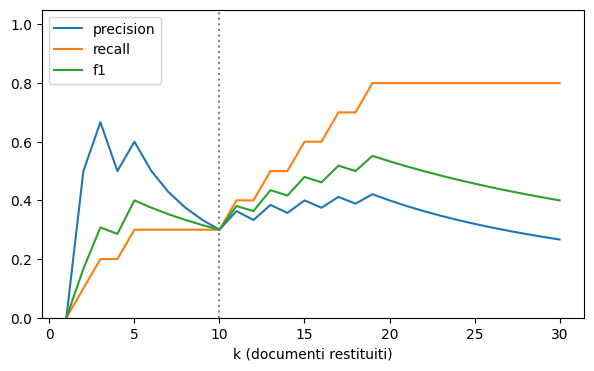

In [9]:
def curva(query, schema, ks):
    return pd.DataFrame({k: metriche(*confusione(query, schema, k)) for k in ks}).T[['precision', 'recall', 'f1']]

ks = range(1, 31)
c = curva(query, 'tfidf', ks)

fig, ax = plt.subplots(figsize=(7, 4))
c.plot(ax=ax)
ax.axvline(len(rilevanti[query]), color='gray', linestyle=':')
ax.set_xlabel('k (documenti restituiti)')
ax.set_ylim(0, 1.05)
plt.show()

### Il compromesso

- Come si muove la precision quando k aumenta? E la recall?
- Perché la recall non può mai scendere mentre la precision può salire e scendere?
- La linea tratteggiata marca il numero di documenti rilevanti. Che cosa succede a F1 vicino a quel punto?
- Un archivista che deve trovare **tutto** quello che esiste su un tema e un utente che vuole **una** risposta giusta sceglierebbero lo stesso k? Perché?

## Cinquanta query, due motori

Una sola query non basta per dire quale motore è migliore: potremmo aver scelto proprio quella in cui uno dei due va bene per caso. Valutiamo tutte le 50 query. Per ciascuna calcoliamo precision, recall e F1 con k = 10 e poi facciamo la **media** sulle query.

In [10]:
def valuta_tutte(schema, k=10):
    return pd.DataFrame({q: metriche(*confusione(q, schema, k)) for q in rilevanti}).T

risultati_tf = valuta_tutte('tf')
risultati_tfidf = valuta_tutte('tfidf')

confronto = pd.DataFrame({
    'tf': risultati_tf[['precision', 'recall', 'f1']].mean(),
    'tf-idf': risultati_tfidf[['precision', 'recall', 'f1']].mean(),
})
confronto.round(3)

,tf,tf-idf
precision,0.25,0.286
recall,0.38,0.416
f1,0.28,0.320


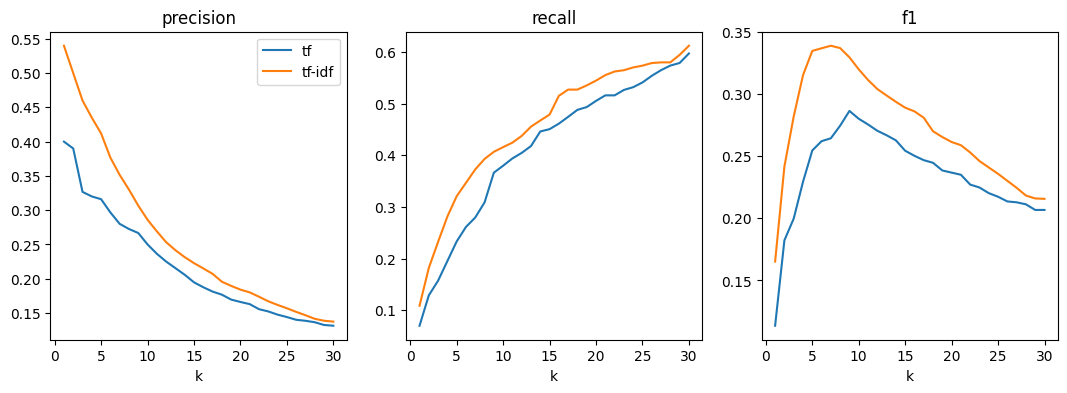

In [11]:
ks = range(1, 31)
fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for schema, etichetta in [('tf', 'tf'), ('tfidf', 'tf-idf')]:
    medie = pd.concat([valuta_tutte(schema, k).mean().rename(k) for k in ks], axis=1).T
    for ax, misura in zip(axs, ['precision', 'recall', 'f1']):
        ax.plot(medie.index, medie[misura], label=etichetta)
        ax.set_title(misura)
        ax.set_xlabel('k')
axs[0].legend()
plt.show()

### Quale motore è migliore

- Su quale misura la differenza tra i due motori è più grande, e per quali valori di k?
- Le curve si incrociano da qualche parte? Che cosa significherebbe per chi sceglie il motore?
- Le differenze nelle medie sono sufficienti per dire che tf-idf è meglio? Come controlliamo che non dipendano da poche query?
- Anche il motore migliore ha un F1 lontano da 1. Da che cosa dipende? Pensate al numero di documenti rilevanti per query e al valore di k.

## Query per query

Le medie nascondono le differenze. Mettiamo in un grafico, per ogni query, l'F1 del motore tf contro quello del motore tf-idf. I punti **sopra** la diagonale sono query in cui vince tf-idf, quelli **sotto** quelle in cui vince tf.

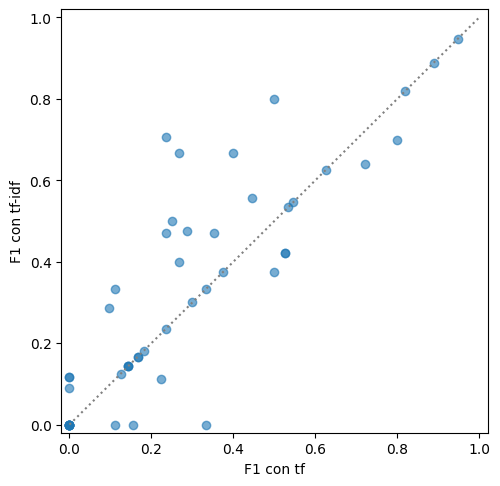

vince tf-idf: 15 | pareggio: 26 | vince tf: 9


In [12]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(risultati_tf['f1'], risultati_tfidf['f1'], alpha=0.6)
ax.plot([0, 1], [0, 1], color='gray', linestyle=':')
ax.set_xlabel('F1 con tf')
ax.set_ylabel('F1 con tf-idf')
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
plt.show()

differenza = risultati_tfidf['f1'] - risultati_tf['f1']
print('vince tf-idf:', int((differenza > 0).sum()), '| pareggio:', int((differenza == 0).sum()), '| vince tf:', int((differenza < 0).sum()))

In [13]:
tabella = pd.DataFrame({'f1 tf': risultati_tf['f1'], 'f1 tf-idf': risultati_tfidf['f1'], 'differenza': differenza}).round(2)
print('Dove tf-idf migliora di più')
print(tabella.sort_values('differenza', ascending=False).head(5).to_string())
print('\nDove tf-idf peggiora')
print(tabella.sort_values('differenza').head(5).to_string())

Dove tf-idf migliora di più
                               f1 tf  f1 tf-idf  differenza
brezza marina e sole            0.24       0.71        0.47
permafrost e suolo ghiacciato   0.27       0.67        0.40
cielo coperto e nebbia          0.50       0.80        0.30
foresta pluviale e umidità      0.40       0.67        0.27
monsone e piogge torrenziali    0.25       0.50        0.25

Dove tf-idf peggiora
                                       f1 tf  f1 tf-idf  differenza
nebbia costiera senza pioggia           0.33       0.00       -0.33
città desertiche in Nord America        0.15       0.00       -0.15
gelo estremo e temperature sotto zero   0.50       0.37       -0.13
estati moderate e inverni freddi        0.53       0.42       -0.11
città tropicali in Asia                 0.11       0.00       -0.11


### Dove aiuta e dove no

- La maggior parte dei punti sta sopra o sotto la diagonale? Ci sono punti sulla diagonale: che cosa vuol dire?
- Leggete le query in cui tf-idf migliora di più. Che cosa hanno in comune? Contengono parole molto comuni?
- Leggete quelle in cui peggiora. Perché l'idf può penalizzare una query?
- Quante query avrebbero bisogno di un altro motore, non solo di un altro peso?

## Quando il motore non può farcela

Alcune query hanno un F1 vicino a zero con entrambi i motori. Separiamo le query **geografiche** (che parlano di dove si trova la città) dalle altre e confrontiamo le medie.

In [14]:
geografiche = [q for q in rilevanti if q.startswith(('città', 'isole'))]
altre = [q for q in rilevanti if q not in geografiche]

pd.DataFrame({
    'numero query': [len(geografiche), len(altre)],
    'f1 tf': [risultati_tf.loc[geografiche, 'f1'].mean(), risultati_tf.loc[altre, 'f1'].mean()],
    'f1 tf-idf': [risultati_tfidf.loc[geografiche, 'f1'].mean(), risultati_tfidf.loc[altre, 'f1'].mean()],
}, index=['geografiche', 'altre']).round(3)

,numero query,f1 tf,f1 tf-idf
geografiche,18,0.060,0.052
altre,32,0.404,0.470


In [15]:
q_geo = 'città tropicali in Asia'
print(q_geo)
print('rilevanti:', sorted(rilevanti[q_geo]))
print()
mostra_giudizi(q_geo, 'tfidf')

città tropicali in Asia
rilevanti: ['Bangkok', 'Calcutta', 'Colombo', 'Giacarta', 'Ho Chi Minh', 'Manila', 'Mumbai', 'Singapore']



,città,similarità,clima,rilevante
1,Città del Capo,0.208,mediterraneo,no
2,Jakutsk,0.208,polare,no
3,Dar es Salaam,0.172,tropicale,no
4,Ushuaia,0.135,polare,no
5,Vorkuta,0.135,polare,no
6,Cagliari,0.133,mediterraneo,no
7,Assuan,0.130,desertico,no
8,Murmansk,0.128,polare,no
9,Mascate,0.126,desertico,no
10,Norilsk,0.123,polare,no


### I limiti del vettore di parole

- Le query geografiche vanno peggio delle altre? Di quanto?
- Guardate i documenti restituiti per «città tropicali in Asia». Contengono la parola *Asia*? Che cosa hanno in comune con la query?
- Perché il motore non sa che Singapore è in Asia? Dove dovrebbe trovare questa informazione?
- Il motore confronta **parole**, non significati. Quali altri casi, oltre alla geografia, sfuggirebbero a un confronto di questo tipo (sinonimi, parafrasi, negazioni)?

## Un risultato giusto e uno sbagliato

Torniamo alla query «clima caldo e umido tutto l'anno» e guardiamo da vicino due documenti restituiti dal motore tf-idf tra i primi dieci: **Singapore**, un vero positivo, e **Mascate**, un falso positivo. Per ciascuno chiediamo quali parole della query hanno fatto salire il punteggio, usando solo l'incidenza tf-idf (la scomposizione della similarità in contributi delle singole parole, che spieghiamo più avanti), e poi le evidenziamo nel testo.

Singapore (vero positivo): posizione 2, rilevante: True, clima: tropicale
Mascate (falso positivo): posizione 7, rilevante: False, clima: desertico


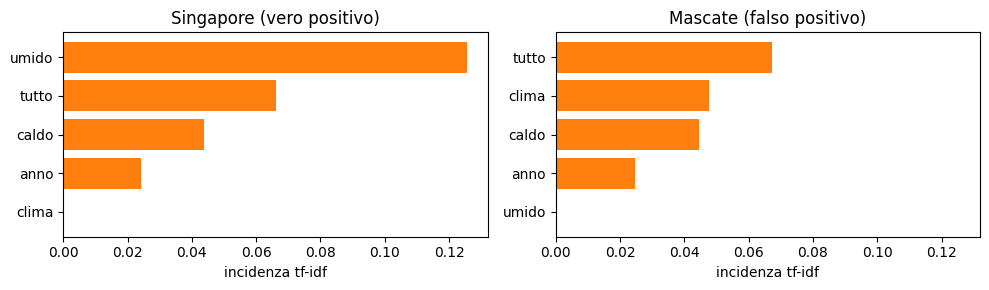

In [16]:
esempi = {'Singapore': 'vero positivo', 'Mascate': 'falso positivo'}
classifica = list(cerca(query, 'tfidf').index)

def incidenze(query, citta):
    v = pd.Series(vettore_query(query, 'tfidf'), index=vocabolario)
    d = tfidf.loc[citta]
    c = v * d / (np.linalg.norm(v) * np.linalg.norm(d))
    return c[v > 0]

inc = pd.DataFrame({n: incidenze(query, n) for n in esempi}).T

for n, esito in esempi.items():
    print(f'{n} ({esito}): posizione {classifica.index(n) + 1}, rilevante: {n in rilevanti[query]}, clima: {clima[n]}')

fig, assi = plt.subplots(1, 2, figsize=(10, 3), sharex=True)
for ax, n in zip(assi, esempi):
    s = inc.loc[n].sort_values()
    ax.barh(s.index, s.values, color='tab:orange')
    ax.set_title(f'{n} ({esempi[n]})')
    ax.set_xlabel('incidenza tf-idf')
plt.tight_layout()
plt.show()

In [17]:
from IPython.display import HTML, display
import html

def evidenzia(citta, incidenze):
    testo = next(voce['testo'] for voce in dataset if voce['citta'] == citta)
    massimo = incidenze.max()
    pezzi = []
    for t in nlp.tokenizer(testo):
        c = incidenze.get(t.text.lower(), 0.0) if t.is_alpha else 0.0
        if c > 0:
            alpha = 0.25 + 0.75 * c / massimo
            pezzi.append(f'<mark style="background: rgba(255, 165, 0, {alpha:.2f}); color: inherit; padding: 0 2px">{html.escape(t.text)}</mark>{t.whitespace_}')
        else:
            pezzi.append(html.escape(t.text_with_ws))
    return f'<p><b>{citta}</b> ({esempi[citta]})<br>{"".join(pezzi)}</p>'

display(HTML(''.join(evidenzia(n, inc.loc[n]) for n in esempi)))

### Perché è giusto, perché è sbagliato

- Quali parole della query pesano di più in **Singapore**? Sono le stesse che pesano in **Mascate**?
- Mascate è un falso positivo ma ha parole in comune con la query. Quali? Che cosa manca al motore per accorgersi che «caldo e secco» non è «caldo e umido»?
- Quali parole evidenziate nel testo sono davvero quelle che esprimono la domanda? Quali sono evidenziate ma poco informative?
- Il motore ha un modo per sapere che *umido* e *secco* si escludono? Che cosa ci dice sul confronto tra parole e significati?

## Provate voi: query libere

Il motore è pronto. Scrivete una query a piacere nella variabile `query_libera`, eseguite la cella e confrontate le prime dieci risposte dei due motori. Le parole che non sono nel vocabolario vengono segnalate e ignorate. Cambiate il testo e rieseguite quante volte volete.

Provate query sul clima («estati calde e asciutte»), query con parole comuni, query con una parola sola, query con parole che non esistono nel corpus.

In [22]:
query_libera = 'una città con la neve in europa'

parole = token_alfabetici(query_libera)
fuori = [p for p in parole if p not in vocabolario]
if fuori:
    print('parole ignorate (fuori vocabolario):', fuori)

pd.concat({'tf': mostra(query_libera, 'tf'), 'tf-idf': mostra(query_libera, 'tfidf')}, axis=1)

parole ignorate (fuori vocabolario): ['europa']


tf                               tf-idf                      
           città similarità      clima          città similarità      clima
1        L'Avana      0.369  tropicale        Vorkuta      0.219     polare
2        Norilsk      0.301     polare   Port Moresby      0.209  tropicale
3       Murmansk      0.298     polare          Lagos      0.203  tropicale
4        Jakutsk      0.298     polare        Jakutsk      0.201     polare
5   Port Moresby      0.293  tropicale        Norilsk      0.197     polare
6          Lagos      0.276  tropicale       Murmansk      0.186     polare
7        Dublino      0.276  temperato  Dar es Salaam      0.179  tropicale
8        Vorkuta      0.272     polare         Assuan      0.176  desertico
9        Seattle      0.265  temperato   Longyearbyen      0.170     polare
10  Longyearbyen      0.261     polare         Agadez      0.153  desertico

### Quanto ha inciso ogni parola

Per ciascuno dei primi cinque documenti scomponiamo il punteggio nei contributi delle singole parole della query. Le parole fuori vocabolario hanno incidenza **zero**, e così quelle con idf zero nel motore tf-idf.

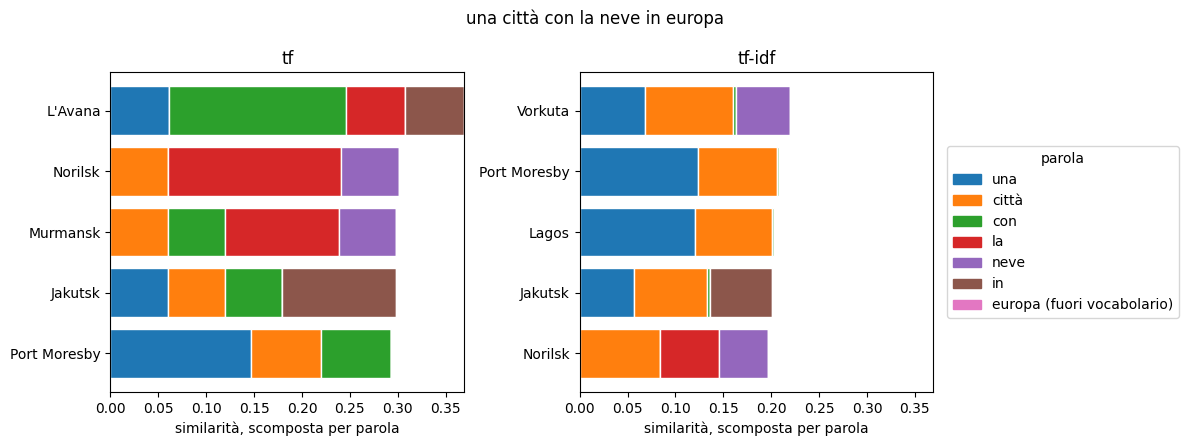

una  città    con     la   neve     in  europa
tf     L'Avana       0.062  0.000  0.185  0.062  0.000  0.062     0.0
       Norilsk       0.000  0.060  0.000  0.181  0.060  0.000     0.0
       Murmansk      0.000  0.060  0.060  0.119  0.060  0.000     0.0
tf-idf Vorkuta       0.069  0.092  0.003  0.000  0.056  0.000     0.0
       Port Moresby  0.124  0.083  0.002  0.000  0.000  0.000     0.0
       Lagos         0.120  0.081  0.002  0.000  0.000  0.000     0.0

In [23]:
def contributi(query, schema, k=5):
    X = (tf if schema == 'tf' else tfidf).values
    v = vettore_query(query, schema)
    parole_query = list(dict.fromkeys(token_alfabetici(query)))
    tabella = pd.DataFrame(0.0, index=nomi, columns=parole_query)
    posizioni = np.flatnonzero(v)
    prodotti = (X[:, posizioni] / np.linalg.norm(X, axis=1, keepdims=True)) * (v[posizioni] / np.linalg.norm(v))
    for colonna, j in enumerate(posizioni):
        tabella[vocabolario[j]] = prodotti[:, colonna]
    ordine = tabella.sum(axis=1).sort_values(ascending=False).index[:k]
    return tabella.loc[ordine]

def disegna_contributi(query, k=5):
    parole_query = list(dict.fromkeys(token_alfabetici(query)))
    colori = dict(zip(parole_query, plt.cm.tab10(np.arange(len(parole_query)) % 10)))
    fig, assi = plt.subplots(1, 2, figsize=(12, 3 + 0.3 * k), sharex=True)
    for ax, (schema, titolo) in zip(assi, [('tf', 'tf'), ('tfidf', 'tf-idf')]):
        t = contributi(query, schema, k)
        sinistra = np.zeros(len(t))
        for p in t.columns:
            ax.barh(t.index, t[p], left=sinistra, color=colori[p], edgecolor='white')
            sinistra += t[p].values
        ax.invert_yaxis()
        ax.set_title(titolo)
        ax.set_xlabel('similarità, scomposta per parola')
    etichette = [p + (' (fuori vocabolario)' if p not in vocabolario else '') for p in parole_query]
    maniglie = [plt.Rectangle((0, 0), 1, 1, color=colori[p]) for p in parole_query]
    assi[1].legend(maniglie, etichette, title='parola', loc='center left', bbox_to_anchor=(1.02, 0.5))
    fig.suptitle(query)
    plt.tight_layout()
    plt.show()

disegna_contributi(query_libera)

pd.concat({'tf': contributi(query_libera, 'tf', 3), 'tf-idf': contributi(query_libera, 'tfidf', 3)}).round(3)

## Come è calcolata l'incidenza

La similarità del coseno tra la query $q$ e un documento $d$ è

$$\cos(q, d) = \frac{\sum_t q_t \, d_t}{\lVert q \rVert \, \lVert d \rVert} = \sum_t \underbrace{\frac{q_t}{\lVert q \rVert} \cdot \frac{d_t}{\lVert d \rVert}}_{c_t}$$

È una somma con un termine per ogni parola $t$ del vocabolario. Chiamiamo **incidenza** della parola $t$ il suo termine $c_t$: la parte di similarità dovuta a quella parola. La somma delle incidenze di tutte le parole dà esattamente la similarità. Per ottenerla seguiamo quattro passi:

1. **Peso nella query** $q_t$: la frequenza relativa della parola nella query (tf), moltiplicata per l'idf del corpus nel motore tf-idf.
2. **Peso nel documento** $d_t$: il valore della stessa colonna nella tabella tf o tf-idf.
3. **Normalizzazione:** si dividono i due pesi per le lunghezze dei vettori, $\lVert q \rVert$ e $\lVert d \rVert$. Così l'incidenza non dipende dalla lunghezza della query né di quella del documento.
4. **Prodotto:** $c_t = \frac{q_t}{\lVert q \rVert} \cdot \frac{d_t}{\lVert d \rVert}$.

Una parola ha incidenza **zero** se manca dal documento ($d_t = 0$), se è fuori dal vocabolario (non ha una colonna, quindi non entra nel vettore della query) oppure se il suo idf è zero (compare in tutti i documenti, quindi nel motore tf-idf $q_t = d_t = 0$). Rifacciamo il conto a mano per una parola e un documento.

In [20]:
schema = 'tfidf'
documento = cerca(query_libera, schema).index[0]
parola_esempio = contributi(query_libera, schema, 1).iloc[0].idxmax()

X = tf if schema == 'tf' else tfidf
v = pd.Series(vettore_query(query_libera, schema), index=vocabolario)

q_t, norma_q = v[parola_esempio], np.linalg.norm(v)
d_t, norma_d = X.loc[documento, parola_esempio], np.linalg.norm(X.loc[documento])

print('documento:', documento, '| parola:', parola_esempio, '| motore:', schema)
print(f'peso nella query     q_t = {q_t:.4f}   lunghezza della query     = {norma_q:.4f}')
print(f'peso nel documento   d_t = {d_t:.4f}   lunghezza del documento   = {norma_d:.4f}')
print(f'incidenza  c_t = ({q_t:.4f} / {norma_q:.4f}) * ({d_t:.4f} / {norma_d:.4f}) = {q_t / norma_q * d_t / norma_d:.4f}')

print()
print('somma delle incidenze del documento:', round(contributi(query_libera, schema, 1).iloc[0].sum(), 4))
print('similarità calcolata dal motore:    ', round(cerca(query_libera, schema).iloc[0], 4))

documento: Port Moresby | parola: una | motore: tfidf
peso nella query     q_t = 0.3054   lunghezza della query     = 0.7468
peso nel documento   d_t = 0.1264   lunghezza del documento   = 0.5054
incidenza  c_t = (0.3054 / 0.7468) * (0.1264 / 0.5054) = 0.1023

somma delle incidenze del documento: 0.2469
similarità calcolata dal motore:     0.2469


### Leggere le incidenze

- Nel grafico tf, quali parole occupano la maggior parte della barra? Sono quelle che ci interessano?
- Nel grafico tf-idf, come cambia la scomposizione? Quali parole contano di più ora?
- Quale parola ha incidenza zero in entrambi i motori? E quale solo nel tf-idf? Perché?
- Il primo documento dei due motori è lo stesso? Se no, quale parola ha fatto la differenza?
- Che cosa succede alle incidenze se raddoppiamo la query (ogni parola scritta due volte)? Perché?
- Cambiate `query_libera` con una query dei notebook precedenti (per esempio «città tropicali in Asia») e rieseguite le celle: da quali parole dipende un risultato sbagliato?
- Provate query con una sola parola comune (*e*), con un sinonimo («afa» invece di «umido»), con una parola inesistente. Come si comportano i due motori?
- Se un utente vedesse questo grafico accanto alla risposta, potrebbe capire perché un documento è stato restituito? Che valore ha poter spiegare il risultato di un motore?

## Cosa abbiamo imparato

1. Una **query** si tratta come un documento: si divide in token e si trasforma in un vettore nello stesso spazio. Le parole fuori vocabolario si perdono. Con tf-idf i pesi della query usano l'**idf del corpus**.
2. Un **motore di ricerca** ordina i documenti per similarità del coseno con la query e ne restituisce i primi k.
3. Per valutarlo servono **giudizi di rilevanza** decisi da persone. Il risultato di ogni misura dipende da quei giudizi, che possono essere incompleti.
4. La **matrice di confusione** incrocia il giudizio del motore con quello della persona (TP, FP, FN, TN). I veri negativi sono quasi sempre moltissimi: per questo l'accuracy dice poco.
5. **Precision** misura quanto sono puliti i risultati, **recall** quanto è completa la ricerca, **F1** le sintetizza. Variando k precision e recall si muovono in direzioni opposte.
6. Su cinquanta query il motore **tf-idf è mediamente migliore** di quello con la sola tf, ma non su tutte le query. Per decidere serve guardare la distribuzione, non solo la media.
7. Un motore che confronta parole non conosce il significato né il mondo: le query geografiche mostrano dove il vettore di parole smette di bastare. È il punto di partenza per le rappresentazioni che catturano il significato.
8. Il punteggio di un documento si può **scomporre parola per parola**: vedere quali parole della query hanno inciso rende il motore spiegabile, e mostra perché con la sola tf pesano le parole grammaticali.